# baebugs — BioKEA Track A, step 1 (BugSorter) vision lane
Replayable end-to-end run. **Swap data in the first code cell**: an AmScope/USB image (or `CAMERA`), scale,
your sieve/insect YAML, and optionally a BugPicker `objects.jsonl` to use its detector as a measurement source.
With everything `None` it runs on a synthetic tray with known ground truth.

Lanes: **measure → plan sieves → twin preflight → run → verify per fraction → hand off to BugPicker → provenance**.

In [1]:
# ---- swap your data here ----
IMAGE = None            # e.g. "../data/tray_001.jpg"
CAMERA = None           # e.g. 0 for the AmScope MD300A
PX_PER_MM = 40.0        # or None + ARUCO_MM
ARUCO_MM = None         # side length of printed ArUco marker in view
YOLO_WEIGHTS = None     # e.g. "../weights/baebugs-seg.pt"; None = classical only
BUGPICKER_OBJECTS = None  # e.g. "scans/scan_x/objects.jsonl" -> extra measurement source
MESH_IMAGES = {}        # {"SCREEN-1": "../data/screen_backlit.jpg", ...} to calibrate apertures
SIEVES = None           # path to sieves.yaml (None = Track A kit defaults)
INSECTS = None          # path to insects.yaml (None = placeholder analog classes)
SAMPLE_ID = "demo-001"
SEED = 0
PLACE = None            # e.g. "Alameda" -> Essig/Calbug prior (needs internet)
CATALOG_NUMBER = None   # e.g. "EMEC347945" to link provenance to an Essig specimen

In [2]:
import sys, json, cv2, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, "..")
from baebugs.measure import classical_measure, consensus, annotate, px_per_mm_from_aruco
from baebugs.sieve import load_yaml, plan_stack, classify
from baebugs.twin import LabTwin
from baebugs.method import verify, update_margin
from baebugs.synthetic import make_sample

truth = None
if IMAGE:
    img = cv2.imread(IMAGE)
elif CAMERA is not None:
    from baebugs.camera import capture; img = capture(CAMERA)
else:
    img, truth = make_sample(n=30, px_per_mm=PX_PER_MM, seed=SEED, length_range=(1.5, 12.0))  # analog-sized
ppm = PX_PER_MM or px_per_mm_from_aruco(img, ARUCO_MM)
inv = load_yaml(SIEVES) if SIEVES else load_yaml("sieves.yaml")
ins = load_yaml(INSECTS) if INSECTS else load_yaml("insects.yaml")
print("px/mm:", ppm, "| image:", img.shape)

px/mm: 40.0 | image: (900, 1200, 3)


## 0 · Calibrate the sieves (measure real apertures, not nominal ones)

In [3]:
from baebugs.sieve_calibrate import measure_aperture, synthetic_mesh
meshes = {k: cv2.imread(v) for k, v in MESH_IMAGES.items()} or {
    "SCREEN-1": synthetic_mesh(1.2, 0.3, 30), "HEX-2": synthetic_mesh(2.2, 0.4, 30),
    "PERF-5": synthetic_mesh(5.0, 1.5, 30, round_holes=True)}
for sid, mimg in meshes.items():
    r = measure_aperture(mimg, 30 if not MESH_IMAGES else ppm)
    for s in inv["sieves"]:
        if s["id"] == sid and r: s["aperture_mm"] = round(r["aperture_mm"], 3)
    print(sid, r)

SCREEN-1 {'aperture_mm': 1.2, 'p10_mm': 1.2, 'p90_mm': 1.2, 'n_openings': 221, 'cv': 3.70074341541719e-16}
HEX-2 {'aperture_mm': 2.2, 'p10_mm': 2.2, 'p90_mm': 2.2, 'n_openings': 70, 'cv': 6.055761952500857e-16}
PERF-5 {'aperture_mm': 4.9789789835611975, 'p10_mm': 4.9789789835611975, 'p90_mm': 4.9789789835611975, 'n_openings': 12, 'cv': 0.0}


## 1 · Observe — two independent measurements + consensus

24 bodies, 0 flagged for review


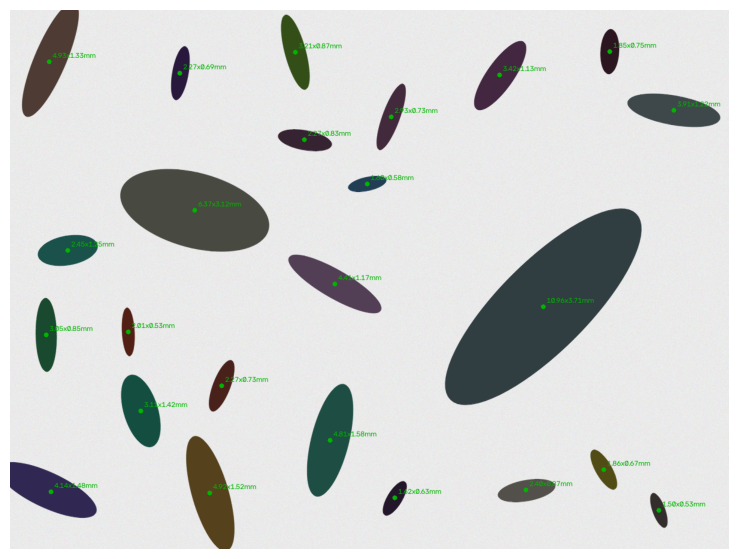

In [4]:
B = classical_measure(img, ppm)
ms = B
if YOLO_WEIGHTS:
    from baebugs.measure import YoloMeasurer
    ms = consensus(YoloMeasurer(YOLO_WEIGHTS)(img, ppm), B, ppm)
if BUGPICKER_OBJECTS:
    from baebugs.bugpicker_bridge import read_bugpicker_objects
    ms = consensus(read_bugpicker_objects(BUGPICKER_OBJECTS), ms, ppm)
flagged = [m for m in ms if m.flag]
print(f"{len(ms)} bodies, {len(flagged)} flagged for review")
plt.figure(figsize=(10,7)); plt.imshow(cv2.cvtColor(annotate(img, ms), cv2.COLOR_BGR2RGB)); plt.axis("off");

median |error|  length 0.6%   width 1.2%
{'tiny': 15, 'small': 7, 'medium': 2, 'large': 0, 'unclassified': 0}


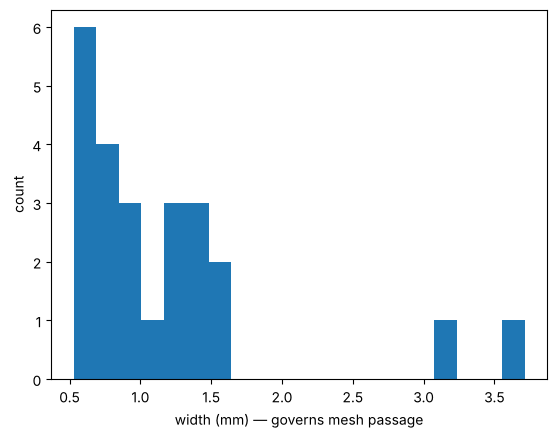

In [5]:
if truth:
    errs = []
    for t in truth:
        m = min(ms, key=lambda m: np.hypot(m.cx-t['cx'], m.cy-t['cy']))
        errs.append((m.length_mm/t['length_mm']-1, m.width_mm/t['width_mm']-1))
    e = np.array(errs)
    print(f"median |error|  length {np.median(abs(e[:,0])):.1%}   width {np.median(abs(e[:,1])):.1%}")
widths = [m.width_mm for m in ms if not m.flag]
plt.hist(widths, bins=20); plt.xlabel("width (mm) — governs mesh passage"); plt.ylabel("count");
print({c: sum(classify(w, ins['classes'])==c for w in widths) for c in [k['name'] for k in ins['classes']]+['unclassified']})

## 1b · Prior from the Essig Museum / Calbug: does this sample look like its locality?

In [6]:
from baebugs import calbug
if PLACE:
    comp = calbug.family_composition(PLACE)
    print("Essig families:", dict(list(comp.items())[:10]))
else:   # offline demo composition
    comp = {"Chironomidae": 600, "Formicidae": 300, "Carabidae": 100}
exp = calbug.expected_class_mix(comp, insects=ins)
print(json.dumps(calbug.compare(exp, widths, insects=ins), indent=1))

{
 "tv_distance": 0.166,
 "flag": false,
 "expected": {
  "medium": 0.1162,
  "tiny": 0.6173,
  "large": 0.0574,
  "small": 0.1332,
  "unclassified": 0.0759
 },
 "observed": {
  "tiny": 0.625,
  "small": 0.2916666666666667,
  "medium": 0.08333333333333333
 }
}


## 2 · Hypothesize — sieve stack + water flow

In [7]:
plan = plan_stack(widths, inv, ins)
print(json.dumps(plan.to_dict(), indent=2))

{
  "steps": [
    {
      "sieve_id": "HEX-2",
      "aperture_mm": 2.2,
      "slot": "A3",
      "purpose": "retain width >= 2.420 mm",
      "flow_l_per_min": 1.5,
      "rinse_l": 0.5,
      "expected_count": 2
    },
    {
      "sieve_id": "SCREEN-1",
      "aperture_mm": 1.2,
      "slot": "A4",
      "purpose": "retain width >= 1.320 mm",
      "flow_l_per_min": 1.2,
      "rinse_l": 0.5,
      "expected_count": 5
    },
    {
      "sieve_id": "TRAY",
      "aperture_mm": 0.0,
      "slot": "B1",
      "purpose": "retain width >= 0.000 mm",
      "flow_l_per_min": 0.25,
      "rinse_l": 0.5,
      "expected_count": 17
    }
  ],
  "passthrough_expected": 0,
  "water_l": 1.5,
  "notes": [
    "no sieve left to split at width 0.528 mm"
  ]
}


## 3 · Preflight against the lab twin (nothing reaches the arm unless this is clean)

In [8]:
twin = LabTwin(inv, log_path="../runs/notebook_actions.jsonl")
errs = twin.preflight(plan)
print("preflight:", errs or "OK")
if not errs:
    twin.execute(plan, robot=None, dry_run=True)   # pass a RobotAdapter + dry_run=False on the bench
    print("water left:", round(twin.state['water']['reservoir_l'], 2), "L")

preflight: OK
water left: 3.5 L


## 4 · Verify & update
After the run, image each sieve's fraction and count it (re-run section 1 per fraction).
Here we simulate the bench retaining a little more than predicted on the top sieve.

In [9]:
observed = {s.sieve_id: s.expected_count for s in plan.steps}
if plan.steps: observed[plan.steps[0].sieve_id] += 2   # <- replace with real counts
v = verify(plan, observed, observed_passthrough=plan.passthrough_expected)
for x in v: print(f"{x.sieve_id:6s} predicted {x.predicted:3d} observed {x.observed:3d} error {x.error:+d}")
new_margin = update_margin(ins['retention_margin'], v)
print("retention_margin:", ins['retention_margin'], "->", round(new_margin, 3))
twin.release(plan)

HEX-2  predicted   2 observed   4 error +2
SCREEN-1 predicted   5 observed   5 error +0
TRAY   predicted  17 observed  17 error +0
drain  predicted   0 observed   0 error +0
retention_margin: 1.1 -> 1.045


## 5 · Hand off to BugPicker (its own `manifest.jsonl` / `objects.jsonl` protocol)

In [10]:
from baebugs.bugpicker_bridge import manifest_record, object_records, write_scan
from collections import Counter
frames, objs = [], []
m_ = ins['retention_margin']
for i, st in enumerate(plan.steps):
    upper = plan.steps[i-1].aperture_mm * m_ if i else float('inf')
    keep = [m for m in ms if not m.flag and st.aperture_mm * m_ <= m.width_mm < upper]
    # label the fraction by what it actually holds (majority size class)
    label = Counter(classify(m.width_mm, ins['classes']) for m in keep).most_common(1)
    # on the bench: image this sieve's fraction and re-measure; here we reuse the tray image
    fr = manifest_record(f"frames/{st.sieve_id}.png", i, ppm, img.shape,
                         tray_size_class=label[0][0] if label else "empty", sorting_tray_slot=i + 1)
    frames.append(fr)
    objs += object_records(keep, fr, start_index=len(objs))
    print(f"{st.sieve_id:9s} slot {i+1}  {fr['tray_size_class']:7s} {len(keep)} objects")
scan = write_scan(f"../runs/scan_{SAMPLE_ID}", frames, objs)
print(scan)

HEX-2     slot 1  medium  2 objects
SCREEN-1  slot 2  small   5 objects
TRAY      slot 3  tiny    17 objects
../runs/scan_demo-001


## 6 · Provenance (hash-chained, FAIR by construction)

In [11]:
from baebugs.provenance import Provenance
prov = Provenance("../runs/provenance.jsonl")
prov.record("measure", SAMPLE_ID, {"px_per_mm": ppm, "yolo": YOLO_WEIGHTS}, inputs=calbug.essig_catalog_ref(CATALOG_NUMBER) if CATALOG_NUMBER else {}, outputs={"n": len(ms)})
prov.record("plan", SAMPLE_ID, outputs=plan.to_dict())
prov.record("verify", SAMPLE_ID, outputs={"new_retention_margin": new_margin})
prov.record("handoff_bugpicker", SAMPLE_ID, outputs={"scan_dir": str(scan), "objects": len(objs)})
print("chain verified:", prov.verify(), "| records for sample:", len(prov.trace(SAMPLE_ID)))

chain verified: True | records for sample: 16
